In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df=pd.read_csv('/content/drive/MyDrive/train.csv',usecols=['Age','Fare','Survived'])

In [5]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [6]:
df.shape

(891, 3)

In [7]:
# drop missing values rows
df.dropna(inplace=True)

In [8]:
df.shape

(714, 3)

In [9]:
X=df[['Age','Fare']]
Y=df[['Survived']]

In [10]:
# train test split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [11]:
X_train,X_test

(      Age      Fare
 328  31.0   20.5250
 73   26.0   14.4542
 253  30.0   16.1000
 719  33.0    7.7750
 666  25.0   13.0000
 ..    ...       ...
 92   46.0   61.1750
 134  25.0   13.0000
 337  41.0  134.5000
 548  33.0   20.5250
 130  33.0    7.8958
 
 [571 rows x 2 columns],
       Age     Fare
 149  42.0  13.0000
 407   3.0  18.7500
 53   29.0  26.0000
 369  24.0  69.3000
 818  43.0   6.4500
 ..    ...      ...
 819  10.0  27.9000
 164   1.0  39.6875
 363  35.0   7.0500
 56   21.0  10.5000
 136  19.0  26.2833
 
 [143 rows x 2 columns])

In [12]:
X_train.head(2)

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542


In [13]:
# defining object for decision tree classifier
clf=DecisionTreeClassifier()

In [14]:
clf.fit(X_train,Y_train)

DecisionTreeClassifier()

In [15]:
y_pred=clf.fit(X_train,Y_train)
y_pred=clf.predict(X_test)

In [16]:
accuracy_score(Y_test,y_pred)

0.6363636363636364

In [17]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,Y,cv=10,scoring='accuracy'))

np.float64(0.6344874804381846)

Applying KBins Discretizer

In [18]:
kbin_age=KBinsDiscretizer(n_bins=5,encode='ordinal',strategy='quantile')
kbin_fare=KBinsDiscretizer(n_bins=5,encode='ordinal',strategy='quantile')

In [20]:
trf=ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_fare,[1])
])

In [21]:
X_train_trf=trf.fit_transform(X_train)
X_test_trf=trf.transform(X_test)

In [24]:
trf.named_transformers_['first'].n_bins_

array([5])

In [26]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42, 19.  , 25.  , 32.  , 42.  , 80.  ])], dtype=object)

In [27]:
trf.named_transformers_['second'].bin_edges_

array([array([  0.    ,   7.8958,  13.    ,  26.    ,  51.4792, 512.3292])],
      dtype=object)

In [28]:
output=pd.DataFrame({
    "age":X_train['Age'],
    "age_trf":X_train_trf[:,0],
    "fare":X_train['Fare'],
    "fare_trf":X_train_trf[:,1],

})

In [31]:
output['age_labels']=pd.cut(x=X_train['Age'],bins=trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels']=pd.cut(x=X_train['Fare'],bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [32]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
234,24.0,1.0,10.5000,1.0,"(19.0, 25.0]","(7.896, 13.0]"
362,45.0,4.0,14.4542,2.0,"(42.0, 80.0]","(13.0, 26.0]"
424,18.0,0.0,20.2125,2.0,"(0.42, 19.0]","(13.0, 26.0]"
784,25.0,2.0,7.0500,0.0,"(19.0, 25.0]","(0.0, 7.896]"
504,16.0,0.0,86.5000,4.0,"(0.42, 19.0]","(51.479, 512.329]"


In [34]:
clf=DecisionTreeClassifier()
clf.fit(X_train_trf,Y_train)
y_pred2=clf.predict(X_test_trf)

In [35]:
accuracy_score(Y_test,y_pred2)

0.6433566433566433

In [39]:
X_trf=trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(),X,Y,cv=10,scoring='accuracy'))

np.float64(0.6275234741784038)

0.6358763693270735


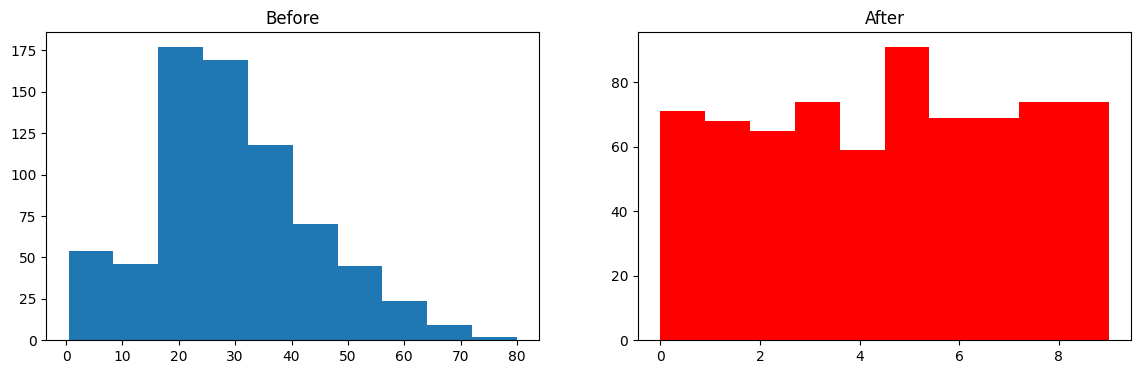

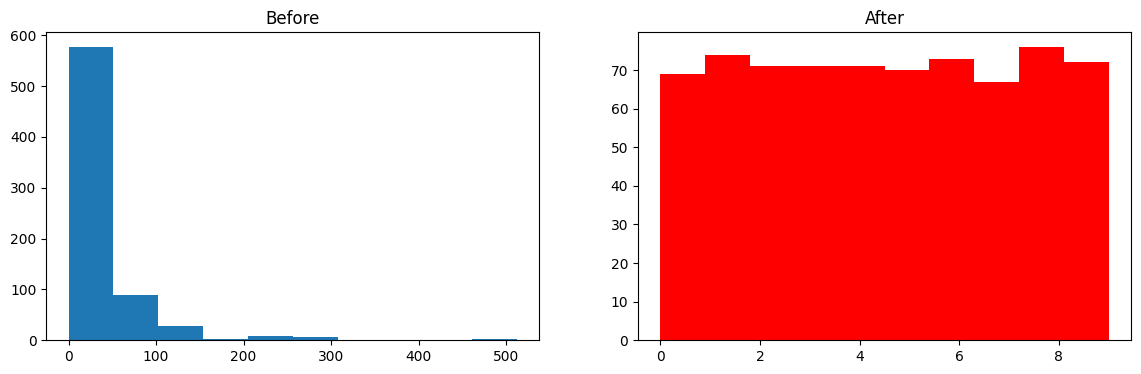

In [48]:
def discretize(bins,strategy):
  kbin_age=KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
  kbin_fare=KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)

  trf=ColumnTransformer([
      ('first',kbin_age,[0]),
      ('second',kbin_fare,[1])
  ])

  X_trf=trf.fit_transform(X)
  print(np.mean(cross_val_score(DecisionTreeClassifier(),X,Y,cv=10,scoring='accuracy')))

  plt.figure(figsize=(14,4))
  plt.subplot(121)
  plt.hist(X['Age'])
  plt.title('Before')

  plt.subplot(122)
  plt.hist(X_trf[:,0],color='red')
  plt.title('After')

  plt.figure(figsize=(14,4))
  plt.subplot(121)
  plt.hist(X['Fare'])
  plt.title('Before')

  plt.subplot(122)
  plt.hist(X_trf[:,1],color='red')
  plt.title('After')



  plt.show()



discretize(10,'quantile')



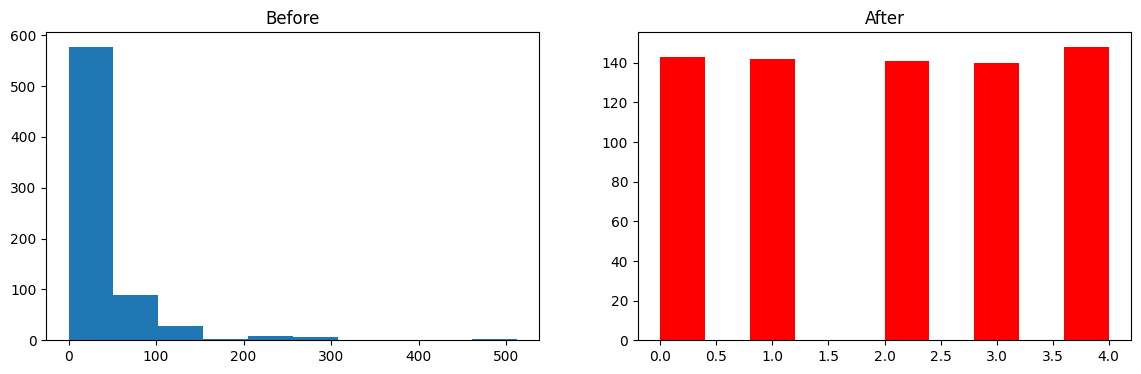

0.6316901408450704


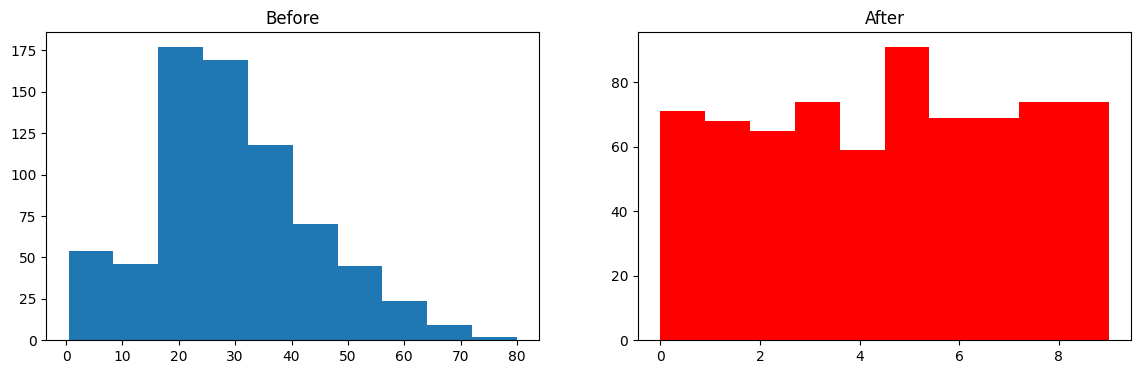

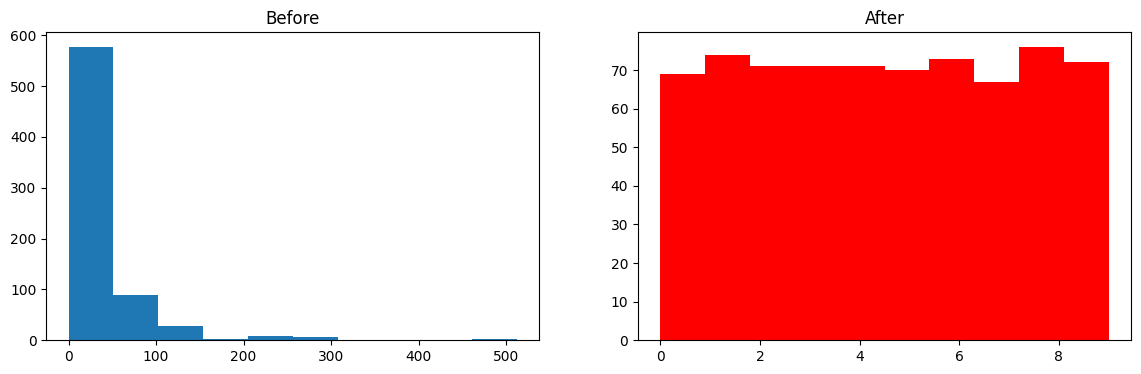

In [50]:
  plt.figure(figsize=(14,4))
  plt.subplot(121)
  plt.hist(X['Fare'])
  plt.title('Before')

  plt.subplot(122)
  plt.hist(X_trf[:,1],color='red')
  plt.title('After')

  plt.show()

discretize(10,'quantile')

0.6246674491392801


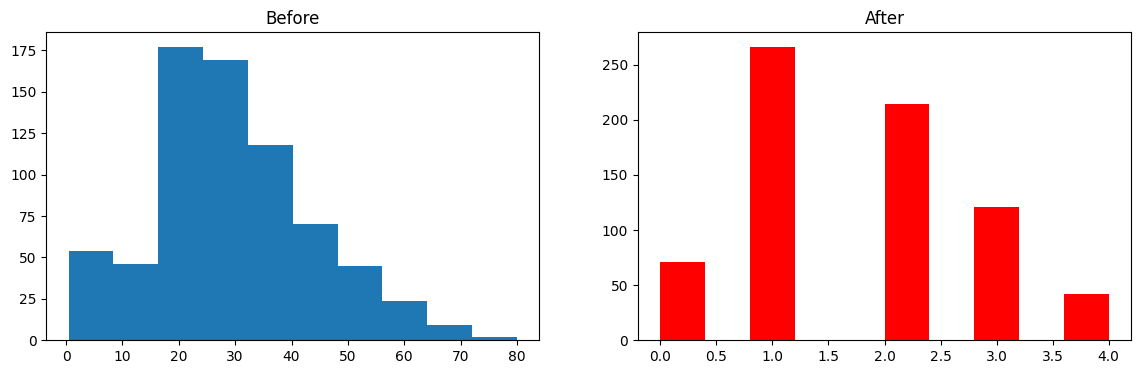

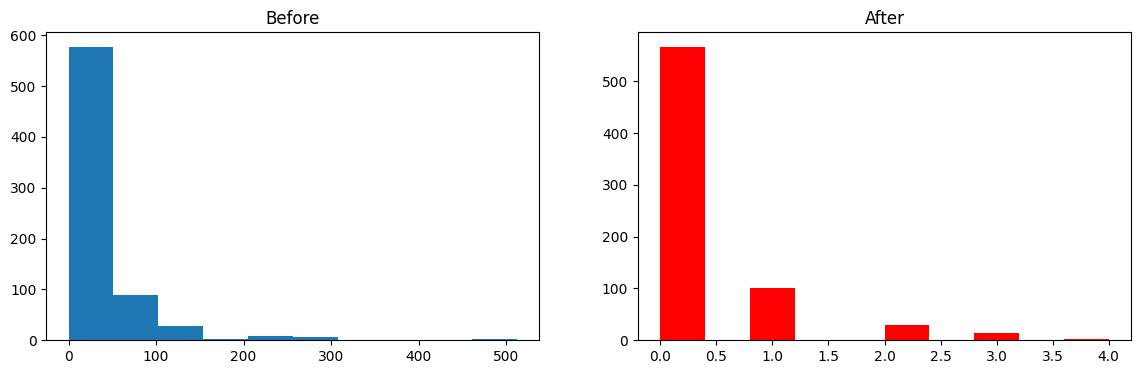

In [49]:
discretize(5,'kmeans')

In [51]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.compose import ColumnTransformer

In [52]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [58]:
df=pd.read_csv('/content/drive/MyDrive/train.csv')[['Age','Fare','SibSp','Parch','Survived']]

In [59]:
df.dropna(inplace=True)

In [60]:
df.head()

,Age,Fare,SibSp,Parch,Survived
0,22.0,7.2500,1,0,0
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,1
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,0


In [62]:
df['Family']=df['SibSp']+df['Parch']
df.head()

,Age,Fare,SibSp,Parch,Survived,Family
0,22.0,7.2500,1,0,0,1
1,38.0,71.2833,1,0,1,1
2,26.0,7.9250,0,0,1,0
3,35.0,53.1000,1,0,1,1
4,35.0,8.0500,0,0,0,0


In [64]:
df.drop(columns=['SibSp','Parch'],inplace=True)
df.head()

,Age,Fare,Survived,Family
0,22.0,7.2500,0,1
1,38.0,71.2833,1,1
2,26.0,7.9250,1,0
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [65]:
X=df[['Age','Fare','Family']]
Y=df[['Survived']]

In [66]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [67]:
X_train.head()

,Age,Fare,Family
328,31.0,20.5250,2
73,26.0,14.4542,1
253,30.0,16.1000,1
719,33.0,7.7750,0
666,25.0,13.0000,0


In [70]:
# without binarization applying decision tree
clf=DecisionTreeClassifier()
clf.fit(X_train,Y_train)
y_pred=clf.predict(X_test)
accuracy_score(Y_test,y_pred)

0.6153846153846154

In [71]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,Y,cv=10,scoring="accuracy"))

np.float64(0.6527190923317685)

In [73]:
from sklearn.preprocessing import Binarizer
trf=ColumnTransformer([
    ('bin',Binarizer(copy=False),['Family'])
],remainder='passthrough')

In [74]:
X_train_trf=trf.fit_transform(X_train)
X_test_trf=trf.fit_transform(X_test)

In [75]:
pd.DataFrame(X_train_trf,columns=['Family','Age','Fare'])

,Family,Age,Fare
0,1.0,31.0,20.5250
1,1.0,26.0,14.4542
2,1.0,30.0,16.1000
3,0.0,33.0,7.7750
4,0.0,25.0,13.0000
...,...,...,...
566,1.0,46.0,61.1750
567,0.0,25.0,13.0000
568,0.0,41.0,134.5000
569,1.0,33.0,20.5250


In [77]:
clf=DecisionTreeClassifier()
clf.fit(X_train_trf,Y_train)
y_pred2=clf.predict(X_test_trf)
accuracy_score(Y_test,y_pred2)

0.6083916083916084